In [3]:
import duckdb
con = duckdb.connect()
con.execute("""
    COPY (SELECT * FROM read_csv_auto('../data/raw/train_ver2.csv', header=true, all_varchar=true))
    TO '../data/processed/train.parquet' (FORMAT PARQUET)
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [4]:
con.execute("SELECT COUNT(*) FROM '../data/processed/train.parquet'").fetchone()

(13647309,)

In [10]:
product_cols = [
    "ind_ahor_fin_ult1", "ind_aval_fin_ult1", "ind_cco_fin_ult1", "ind_cder_fin_ult1",
    "ind_cno_fin_ult1", "ind_ctju_fin_ult1", "ind_ctma_fin_ult1", "ind_ctop_fin_ult1",
    "ind_ctpp_fin_ult1", "ind_deco_fin_ult1", "ind_deme_fin_ult1", "ind_dela_fin_ult1",
    "ind_ecue_fin_ult1", "ind_fond_fin_ult1", "ind_hip_fin_ult1", "ind_plan_fin_ult1",
    "ind_pres_fin_ult1", "ind_reca_fin_ult1", "ind_tjcr_fin_ult1", "ind_valo_fin_ult1",
    "ind_viv_fin_ult1", "ind_nomina_ult1", "ind_nom_pens_ult1", "ind_recibo_ult1",
]

df = pd.read_csv(
    "../data/raw/train_ver2.csv",
    usecols=["fecha_dato", "ncodpers", "sexo", "age", "antiguedad", "renta", "segmento"] + product_cols,
    dtype={**{c: "float32" for c in product_cols},
           "ncodpers": "int32", "fecha_dato": "category",
           "sexo": "category", "segmento": "category",
           "age": "str", "antiguedad": "str", "renta": "str"},
)
df.shape

(13647309, 31)

In [11]:
for c in product_cols:
    df[c] = df[c].fillna(0).astype("int8")

df["fecha_dato"] = pd.to_datetime(df["fecha_dato"])

for c in ["age", "antiguedad", "renta"]:
    df[c] = pd.to_numeric(df[c].str.strip(), errors="coerce").astype("float32")

df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 13647309 entries, 0 to 13647308
Data columns (total 31 columns):
 #   Column             Dtype   
---  ------             -----   
 0   fecha_dato         category
 1   ncodpers           int32   
 2   sexo               category
 3   age                float32 
 4   antiguedad         float32 
 5   renta              float32 
 6   segmento           category
 7   ind_ahor_fin_ult1  int8    
 8   ind_aval_fin_ult1  int8    
 9   ind_cco_fin_ult1   int8    
 10  ind_cder_fin_ult1  int8    
 11  ind_cno_fin_ult1   int8    
 12  ind_ctju_fin_ult1  int8    
 13  ind_ctma_fin_ult1  int8    
 14  ind_ctop_fin_ult1  int8    
 15  ind_ctpp_fin_ult1  int8    
 16  ind_deco_fin_ult1  int8    
 17  ind_deme_fin_ult1  int8    
 18  ind_dela_fin_ult1  int8    
 19  ind_ecue_fin_ult1  int8    
 20  ind_fond_fin_ult1  int8    
 21  ind_hip_fin_ult1   int8    
 22  ind_plan_fin_ult1  int8    
 23  ind_pres_fin_ult1  int8    
 24  ind_reca_fin_ult1  int8    
 25  

In [12]:
df["fecha_dato"] = pd.to_datetime(df["fecha_dato"].astype(str))
df["fecha_dato"].dtype

dtype('<M8[us]')

In [13]:
 df.head()

,fecha_dato,ncodpers,sexo,age,antiguedad,renta,segmento,ind_ahor_fin_ult1,ind_aval_fin_ult1,ind_cco_fin_ult1,...,ind_hip_fin_ult1,ind_plan_fin_ult1,ind_pres_fin_ult1,ind_reca_fin_ult1,ind_tjcr_fin_ult1,ind_valo_fin_ult1,ind_viv_fin_ult1,ind_nomina_ult1,ind_nom_pens_ult1,ind_recibo_ult1
0,2015-01-28,1375586,H,35.0,6.0,87218.101562,02 - PARTICULARES,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,2015-01-28,1050611,V,23.0,35.0,35548.738281,03 - UNIVERSITARIO,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,2015-01-28,1050612,V,23.0,35.0,122179.109375,03 - UNIVERSITARIO,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,2015-01-28,1050613,H,22.0,35.0,119775.539062,03 - UNIVERSITARIO,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2015-01-28,1050614,V,23.0,35.0,NaN,03 - UNIVERSITARIO,0,0,1,...,0,0,0,0,0,0,0,0,0,0


In [14]:
product_names = {
    "ind_ahor_fin_ult1": "savings_account",
    "ind_aval_fin_ult1": "guarantees",
    "ind_cco_fin_ult1": "current_account",
    "ind_cder_fin_ult1": "derivatives_account",
    "ind_cno_fin_ult1": "payroll_account",
    "ind_ctju_fin_ult1": "junior_account",
    "ind_ctma_fin_ult1": "mas_particular_account",
    "ind_ctop_fin_ult1": "particular_account",
    "ind_ctpp_fin_ult1": "particular_plus_account",
    "ind_deco_fin_ult1": "short_term_deposits",
    "ind_deme_fin_ult1": "medium_term_deposits",
    "ind_dela_fin_ult1": "long_term_deposits",
    "ind_ecue_fin_ult1": "e_account",
    "ind_fond_fin_ult1": "funds",
    "ind_hip_fin_ult1": "mortgage",
    "ind_plan_fin_ult1": "pension_plan",
    "ind_pres_fin_ult1": "loans",
    "ind_reca_fin_ult1": "taxes",
    "ind_tjcr_fin_ult1": "credit_card",
    "ind_valo_fin_ult1": "securities",
    "ind_viv_fin_ult1": "home_account",
    "ind_nomina_ult1": "payroll",
    "ind_nom_pens_ult1": "pensions",
    "ind_recibo_ult1": "direct_debit",
}

df.rename(columns={
    "fecha_dato": "date",
    "ncodpers": "customer_id",
    "sexo": "sex",
    "antiguedad": "tenure_months",
    "renta": "income",
    "segmento": "segment",
    **product_names,
}, inplace=True)

product_cols = list(product_names.values())
df.head()

,date,customer_id,sex,age,tenure_months,income,segment,savings_account,guarantees,current_account,...,mortgage,pension_plan,loans,taxes,credit_card,securities,home_account,payroll,pensions,direct_debit
0,2015-01-28,1375586,H,35.0,6.0,87218.101562,02 - PARTICULARES,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,2015-01-28,1050611,V,23.0,35.0,35548.738281,03 - UNIVERSITARIO,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,2015-01-28,1050612,V,23.0,35.0,122179.109375,03 - UNIVERSITARIO,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,2015-01-28,1050613,H,22.0,35.0,119775.539062,03 - UNIVERSITARIO,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2015-01-28,1050614,V,23.0,35.0,NaN,03 - UNIVERSITARIO,0,0,1,...,0,0,0,0,0,0,0,0,0,0


In [15]:
df["segment"] = df["segment"].astype(str).str[:2].map({"01": "Top", "02": "Individuals", "03": "University"}).astype("category")

In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13647309 entries, 0 to 13647308
Data columns (total 31 columns):
 #   Column                   Dtype         
---  ------                   -----         
 0   date                     datetime64[us]
 1   customer_id              int32         
 2   sex                      category      
 3   age                      float32       
 4   tenure_months            float32       
 5   income                   float32       
 6   segment                  category      
 7   savings_account          int8          
 8   guarantees               int8          
 9   current_account          int8          
 10  derivatives_account      int8          
 11  payroll_account          int8          
 12  junior_account           int8          
 13  mas_particular_account   int8          
 14  particular_account       int8          
 15  particular_plus_account  int8          
 16  short_term_deposits      int8          
 17  medium_term_deposits     int8       

In [18]:
df["customer_id"].unique()

array([1375586, 1050611, 1050612, ..., 1173729, 1164094, 1550586],
      shape=(956645,), dtype=int32)

In [20]:
df.describe().round()

,date,customer_id,age,tenure_months,income,savings_account,guarantees,current_account,derivatives_account,payroll_account,...,mortgage,pension_plan,loans,taxes,credit_card,securities,home_account,payroll,pensions,direct_debit
count,13647309,13647309.0,13619575.0,13619575.0,10852934.0,13647309.0,13647309.0,13647309.0,13647309.0,13647309.0,...,13647309.0,13647309.0,13647309.0,13647309.0,13647309.0,13647309.0,13647309.0,13647309.0,13647309.0,13647309.0
mean,2015-10-19 22:37:34.242210,834904.0,40.0,77.0,134254.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
min,2015-01-28 00:00:00,15889.0,2.0,-999999.0,1203.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,2015-06-28 00:00:00,452813.0,24.0,23.0,68711.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
50%,2015-10-28 00:00:00,931893.0,39.0,50.0,101850.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
75%,2016-02-28 00:00:00,1199286.0,50.0,135.0,155956.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,2016-05-28 00:00:00,1553689.0,164.0,256.0,28894396.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
std,NaN,431565.0,17.0,1672.0,230620.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [26]:
df[product_cols].sum().sort_values()

guarantees                     316
savings_account               1396
derivatives_account           5376
medium_term_deposits         22668
short_term_deposits          24275
loans                        35857
home_account                 52511
mortgage                     80336
pension_plan                125159
junior_account              129297
mas_particular_account      132742
funds                       252284
securities                  349475
long_term_deposits          586381
particular_plus_account     591008
credit_card                 605786
taxes                       716980
payroll                     745961
pensions                    810085
payroll_account            1103620
e_account                  1129227
direct_debit               1745712
particular_account         1760616
current_account            8945588
dtype: int64

In [27]:
df.sort_values(["customer_id", "date"], inplace=True)
df.reset_index(drop=True, inplace=True)
df.shape

(13647309, 31)

In [29]:
prev = df[product_cols].shift(1, fill_value=0)

In [30]:
same_customer = df["customer_id"].eq(df["customer_id"].shift(1))

In [31]:
added = df[product_cols].gt(prev)
added.loc[~same_customer, :] = False
del prev

In [32]:
add_counts = added.sum().sort_values()
add_counts

savings_account                 2
guarantees                      4
home_account                   70
mortgage                       75
derivatives_account           136
loans                         147
medium_term_deposits          250
junior_account                490
pension_plan                  618
particular_plus_account      2420
short_term_deposits          3074
funds                        3699
particular_account           3882
securities                   4850
mas_particular_account       7002
taxes                        9238
long_term_deposits          12707
e_account                   26378
payroll_account             37187
credit_card                 69311
current_account             69997
payroll                     73800
pensions                    84768
direct_debit               153205
dtype: int64

In [33]:
pd.DataFrame({"holdings": df[product_cols].sum(), "additions": added.sum()}).sort_values("additions")

,holdings,additions
savings_account,1396,2
guarantees,316,4
home_account,52511,70
mortgage,80336,75
derivatives_account,5376,136
loans,35857,147
medium_term_deposits,22668,250
junior_account,129297,490
pension_plan,125159,618
particular_plus_account,591008,2420


In [34]:
df.groupby("customer_id")["date"].diff().dt.days.value_counts().head(10)

date
31.0     7185226
30.0     3953031
29.0      919070
28.0      625094
61.0        2000
122.0       1398
91.0        1393
150.0       1098
181.0       1038
59.0         286
Name: count, dtype: int64

In [35]:
MIN_ADDITIONS = 1000
keep_products = add_counts[add_counts >= MIN_ADDITIONS].index.tolist()
drop_products = add_counts[add_counts < MIN_ADDITIONS].index.tolist()
len(keep_products), drop_products

(15,
 ['savings_account',
  'guarantees',
  'home_account',
  'mortgage',
  'derivatives_account',
  'loans',
  'medium_term_deposits',
  'junior_account',
  'pension_plan'])

In [36]:
df["income"].isna().mean()
df["income"].isna().groupby(df["segment"], observed=True).mean()
df["income"].isna().groupby(df["date"]).mean()

date
2015-01-28    0.178394
2015-02-28    0.177112
2015-03-28    0.175949
2015-04-28    0.174917
2015-05-28    0.173934
2015-06-28    0.171551
2015-07-28    0.171773
2015-08-28    0.171059
2015-09-28    0.180289
2015-10-28    0.205453
2015-11-28    0.218846
2015-12-28    0.224805
2016-01-28    0.230162
2016-02-28    0.234959
2016-03-28    0.239293
2016-04-28    0.242660
2016-05-28    0.245872
Name: income, dtype: float64

In [37]:
df["income"] = df["income"].fillna(df.groupby("customer_id")["income"].transform("median"))
df["income"].isna().mean()

np.float64(0.20474336735542517)

In [38]:
seg_median = df.groupby("segment", observed=True)["income"].transform("median")
df["income"] = df["income"].fillna(seg_median)
del seg_median
df["income"].isna().sum()

np.int64(132356)

In [39]:
df["income"].quantile([0.01, 0.5, 0.99, 0.999])

0.010    2.799384e+04
0.500    1.045839e+05
0.990    5.067154e+05
0.999    1.359864e+06
Name: income, dtype: float32

In [40]:
cap = df["income"].quantile(0.99)
df["income"] = df["income"].clip(upper=cap)

In [41]:
df.duplicated(["customer_id", "date"]).sum()
df.isna().sum()[lambda s: s > 0]
df.shape

(13647309, 31)

In [42]:
df["income"] = df["income"].fillna(df["income"].median())
df["income"].isna().sum()

np.int64(0)

In [43]:
print(df.duplicated(["customer_id", "date"]).sum())
print(df.isna().sum()[lambda s: s > 0])

0
sex               27804
age               27734
tenure_months     27734
segment          189368
dtype: int64


In [44]:
df["segment"] = df["segment"].cat.add_categories("Unknown").fillna("Unknown")
df["sex"] = df["sex"].cat.add_categories("Unknown").fillna("Unknown")
df["age"] = df["age"].fillna(df["age"].median())
df["tenure_months"] = df["tenure_months"].fillna(df["tenure_months"].median())

In [45]:
print((df["age"] > 100).sum(), (df["tenure_months"] < 0).sum())

12869 38


In [46]:
df.loc[df["age"] > 100, "age"] = np.nan
df.loc[df["tenure_months"] < 0, "tenure_months"] = np.nan
df["age"] = df["age"].fillna(df["age"].median())
df["tenure_months"] = df["tenure_months"].fillna(df["tenure_months"].median())
df[["age", "tenure_months"]].describe()

,age,tenure_months
count,1.364731e+07,1.364731e+07
mean,4.011761e+01,7.932247e+01
std,1.705443e+01,6.632012e+01
min,2.000000e+00,0.000000e+00
25%,2.400000e+01,2.300000e+01
50%,3.900000e+01,5.000000e+01
75%,5.000000e+01,1.350000e+02
max,1.000000e+02,2.560000e+02


In [47]:
print((df["age"] < 18).sum())
print(df.loc[df["age"] < 18, "junior_account"].mean())

118796
0.9090541769083134


In [48]:
df.to_parquet("../data/processed/clean.parquet")
added[keep_products].to_parquet("../data/processed/added.parquet")

In [49]:
df = pd.read_parquet("../data/processed/clean.parquet")
added = pd.read_parquet("../data/processed/added.parquet")

In [50]:
print(df.shape, added.shape)
df.dtypes.value_counts()

(13647309, 31) (13647309, 15)


int8              24
float32            3
datetime64[us]     1
int32              1
category           1
category           1
Name: count, dtype: int64

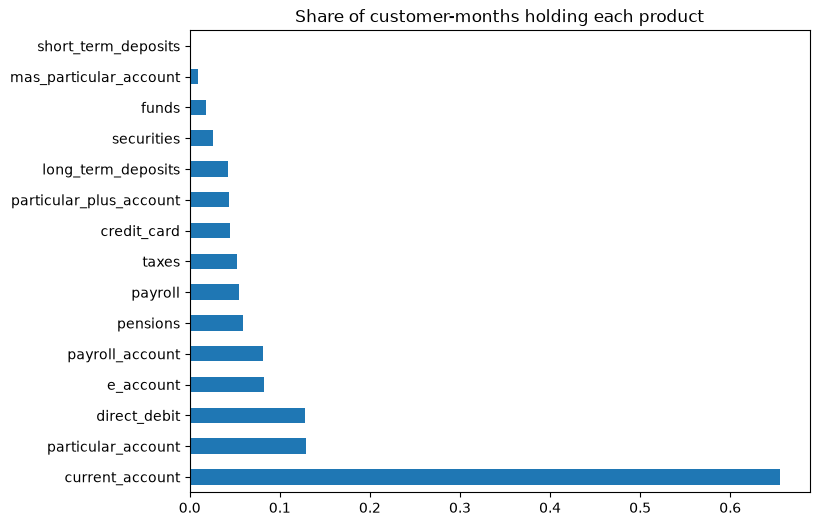

In [51]:
import matplotlib.pyplot as plt
pop = df[keep_products].mean().sort_values(ascending=False)
pop.plot(kind="barh", figsize=(8, 6), title="Share of customer-months holding each product")
plt.show()

In [52]:
df["n_products"] = df[product_cols].sum(axis=1).astype("int8")
df["n_products"].value_counts().sort_index()

n_products
0     2556239
1     7169004
2     1930726
3      770692
4      450017
5      289882
6      210944
7      141484
8       76139
9       33768
10      12682
11       4343
12       1124
13        230
14         26
15          9
Name: count, dtype: int64

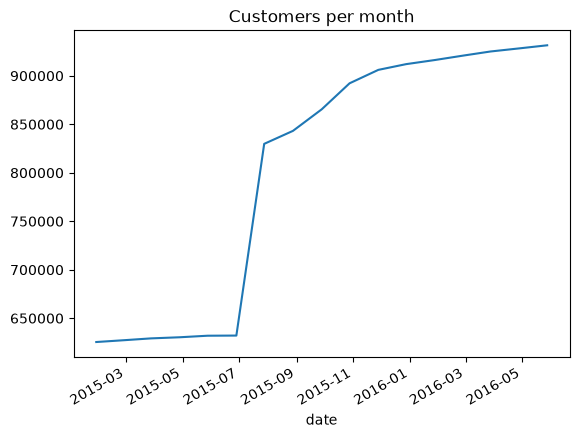

In [53]:
df.groupby("date")["customer_id"].nunique().plot(title="Customers per month")
plt.show()

In [54]:
first_date = df.groupby("customer_id")["date"].transform("min")
new_cust = df[df["date"] == first_date]
new_cust.groupby("date")["tenure_months"].agg(["size", "median"])

,size,median
date,,
2015-01-28,625457,51.0
2015-02-28,4468,5.0
2015-03-28,3976,5.0
2015-04-28,3423,3.0
2015-05-28,3501,2.0
2015-06-28,3217,1.0
2015-07-28,193115,51.0
2015-08-28,14799,0.0
2015-09-28,23598,0.0


In [55]:
zero = df["n_products"] == 0
df.groupby(zero)[["age", "tenure_months"]].median()

,age,tenure_months
n_products,,
False,38.0,48.0
True,41.0,63.0


In [56]:
df.groupby("segment", observed=True)[keep_products].mean().round(3)

age_group = pd.cut(df["age"], [0, 17, 25, 35, 50, 65, 100])
df.groupby(age_group, observed=True)[keep_products].mean().round(3)

,particular_plus_account,short_term_deposits,funds,particular_account,securities,mas_particular_account,taxes,long_term_deposits,e_account,payroll_account,credit_card,current_account,payroll,pensions,direct_debit
age,,,,,,,,,,,,,,,
"(0, 17]",0.000,0.000,0.000,0.000,0.000,0.000,0.001,0.002,0.000,0.000,0.000,0.000,0.000,0.003,0.000
"(17, 25]",0.000,0.000,0.000,0.004,0.001,0.001,0.002,0.001,0.012,0.018,0.001,0.810,0.009,0.009,0.030
"(25, 35]",0.017,0.001,0.004,0.029,0.008,0.010,0.034,0.011,0.058,0.095,0.022,0.722,0.065,0.066,0.142
"(35, 50]",0.080,0.003,0.023,0.194,0.041,0.016,0.101,0.058,0.129,0.131,0.081,0.571,0.096,0.098,0.211
"(50, 65]",0.072,0.003,0.045,0.232,0.052,0.013,0.078,0.089,0.137,0.106,0.082,0.573,0.078,0.084,0.165
"(65, 100]",0.053,0.002,0.038,0.305,0.040,0.011,0.041,0.101,0.105,0.049,0.033,0.549,0.006,0.039,0.078


In [57]:
zero_all = df.groupby("customer_id")["n_products"].max() == 0
print(zero_all.sum(), zero_all.mean())

225483 0.23570185387473933


In [58]:
zero_ids = zero_all[zero_all].index
is_zero = df["customer_id"].isin(zero_ids)

print(df.groupby(is_zero)[["age", "tenure_months", "income"]].median())
print(df[is_zero]["segment"].value_counts(normalize=True).round(3))
print(df[~is_zero]["segment"].value_counts(normalize=True).round(3))
print(df[is_zero].groupby("customer_id").size().describe())

              age  tenure_months         income
customer_id                                    
False        38.0           48.0  104340.296875
True         42.0           68.0  108013.648438
segment
Individuals    0.718
University     0.255
Unknown        0.028
Top            0.000
Name: proportion, dtype: float64
segment
Individuals    0.556
University     0.384
Top            0.050
Unknown        0.011
Name: proportion, dtype: float64
count    225483.000000
mean         10.355796
std           3.018324
min           1.000000
25%          11.000000
50%          11.000000
75%          11.000000
max          17.000000
dtype: float64


segment                  Individuals    Top  University  Unknown
particular_plus_account        0.062  0.153       0.003    0.002
short_term_deposits            0.002  0.014       0.000    0.006
funds                          0.017  0.191       0.001    0.001
particular_account             0.200  0.251       0.006    0.007
securities                     0.028  0.202       0.002    0.001
mas_particular_account         0.013  0.027       0.002    0.014
taxes                          0.070  0.198       0.008    0.055
long_term_deposits             0.037  0.495       0.003    0.003
e_account                      0.099  0.466       0.016    0.007
payroll_account                0.095  0.310       0.034    0.007
credit_card                    0.058  0.205       0.006    0.001
current_account                0.556  0.610       0.829    0.447
payroll                        0.064  0.227       0.021    0.004
pensions                       0.070  0.259       0.022    0.004
direct_debit             

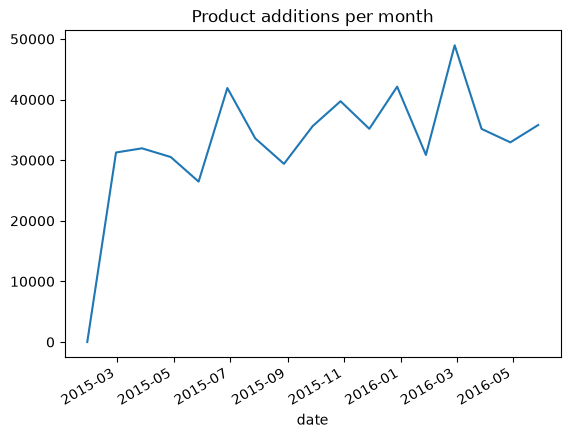

In [59]:
print(df.groupby("segment", observed=True)[keep_products].mean().round(3).T)

added.groupby(df["date"]).sum().sum(axis=1).plot(title="Product additions per month")
plt.show()

In [60]:
first = df.groupby("customer_id")["date"].min()
print(first.loc[zero_ids].value_counts().sort_index())

date
2015-01-28     15826
2015-02-28        86
2015-03-28        88
2015-04-28        68
2015-05-28        50
2015-06-28        29
2015-07-28    173216
2015-08-28      2384
2015-09-28      4475
2015-10-28      9807
2015-11-28      5403
2015-12-28      3043
2016-01-28      2003
2016-02-28      2128
2016-03-28      2092
2016-04-28      1888
2016-05-28      2897
Name: count, dtype: int64


In [61]:
july = pd.Timestamp("2015-07-28")
july_batch = first[first == july].index
july_zero = first.loc[zero_ids][first.loc[zero_ids] == july].index
print(len(july_batch), len(july_zero), len(july_zero) / len(july_batch))

df["exclude_train"] = df["customer_id"].isin(july_zero)
print(df["exclude_train"].mean())

193115 173216 0.8969577712761826
0.13848180619344078


In [62]:
df.to_parquet("../data/processed/clean.parquet")

In [63]:
next_gap = (df["date"].shift(-1) - df["date"]).dt.days
valid = df["customer_id"].eq(df["customer_id"].shift(-1)) & next_gap.between(1, 31)
del next_gap
print(valid.sum(), valid.mean())

12682421 0.929298296096322


In [64]:
train_mask = valid & (df["date"] <= "2016-02-28") & ~df["exclude_train"]
test_mask = valid & (df["date"] >= "2016-03-28") & ~df["exclude_train"]
print(train_mask.sum(), test_mask.sum())

9457325 1508451


In [65]:
target = added[keep_products].shift(-1, fill_value=False)
y_any = target.any(axis=1)
print(y_any[valid].mean())
print(target[valid].mean().sort_values(ascending=False).round(4))

0.0350895936982379
direct_debit               0.0121
pensions                   0.0067
payroll                    0.0058
credit_card                0.0054
current_account            0.0054
payroll_account            0.0029
e_account                  0.0021
long_term_deposits         0.0010
taxes                      0.0007
mas_particular_account     0.0005
securities                 0.0004
particular_account         0.0003
funds                      0.0003
short_term_deposits        0.0002
particular_plus_account    0.0002
dtype: float64


In [67]:
feature_cols = ["age", "tenure_months", "income", "n_products"]

In [69]:
X_train = df.loc[train_mask, feature_cols]
y_train = y_any[train_mask]
X_test = df.loc[test_mask, feature_cols]
y_test = y_any[test_mask]

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(9457325, 4) (1508451, 4)
0.04129560948788373 0.036113204870426685


In [70]:
X_small = X_train.sample(1_000_000, random_state=42)
y_small = y_train.loc[X_small.index]

In [71]:
X_small = X_train.sample(1_000_000, random_state=42)
y_small = y_train.loc[X_small.index]

In [72]:
from sklearn.ensemble import HistGradientBoostingClassifier
model = HistGradientBoostingClassifier(max_iter=100)
model.fit(X_small, y_small)

,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""Categorical"" and ""Enum"" are considered to be categorical features. The input must be a dataframe that is supported by narwhals (or supports it): :func:`narwhals.from_native` must work. This is the case, for instance, for pandas and polars DataFrames.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values. All categorical values areconverted to floating point numbers. This means that categorical valuesof 1.0 and 1 are treated as the same category.Read more in the :ref:`User Guide <categorical_support_gbdt>`... versionadded:: 0.24.. versionchanged:: 1.2 Added support for feature names... versionchanged:: 1.4 Added `""from_dty

In [73]:
scores = model.predict_proba(X_test)[:, 1]

In [74]:
import numpy as np

order = np.argsort(scores)[::-1]      # customer positions, best score first
base = y_test.mean()

for k in [0.01, 0.05, 0.10]:
    top_idx = order[: int(len(scores) * k)]
    rate = y_test.values[top_idx].mean()
    print(k, round(rate, 4), round(rate / base, 2))

0.01 0.3113 8.62
0.05 0.1585 4.39
0.1 0.1258 3.48


In [75]:
feature_cols = ["age", "tenure_months", "income", "n_products"] + keep_products

In [76]:
X_train = df.loc[train_mask, feature_cols]
X_test = df.loc[test_mask, feature_cols]
X_small = X_train.sample(1_000_000, random_state=42)
y_small = y_train.loc[X_small.index]
print(X_train.shape, X_small.shape)

(9457325, 19) (1000000, 19)


In [77]:
model = HistGradientBoostingClassifier(max_iter=100)
model.fit(X_small, y_small)

,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""Categorical"" and ""Enum"" are considered to be categorical features. The input must be a dataframe that is supported by narwhals (or supports it): :func:`narwhals.from_native` must work. This is the case, for instance, for pandas and polars DataFrames.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values. All categorical values areconverted to floating point numbers. This means that categorical valuesof 1.0 and 1 are treated as the same category.Read more in the :ref:`User Guide <categorical_support_gbdt>`... versionadded:: 0.24.. versionchanged:: 1.2 Added support for feature names... versionchanged:: 1.4 Added `""from_dty

In [78]:
scores = model.predict_proba(X_test)[:, 1]
order = np.argsort(scores)[::-1]
base = y_test.mean()

for k in [0.01, 0.05, 0.10]:
    top_idx = order[: int(len(scores) * k)]
    rate = y_test.values[top_idx].mean()
    print(k, round(rate, 4), round(rate / base, 2))

0.01 0.4892 13.55
0.05 0.2636 7.3
0.1 0.1836 5.08


In [79]:
df["segment_code"] = df["segment"].cat.codes.astype("int8")
df["sex_code"] = df["sex"].cat.codes.astype("int8")

In [80]:
feature_cols = ["age", "tenure_months", "income", "n_products", "segment_code", "sex_code"] + keep_products

X_train = df.loc[train_mask, feature_cols]
X_test = df.loc[test_mask, feature_cols]
X_small = X_train.sample(1_000_000, random_state=42)
y_small = y_train.loc[X_small.index]
print(X_train.shape)

(9457325, 21)


In [81]:
model = HistGradientBoostingClassifier(max_iter=100)
model.fit(X_small, y_small)

scores = model.predict_proba(X_test)[:, 1]
order = np.argsort(scores)[::-1]
base = y_test.mean()

for k in [0.01, 0.05, 0.10]:
    top_idx = order[: int(len(scores) * k)]
    rate = y_test.values[top_idx].mean()
    print(k, round(rate, 4), round(rate / base, 2))

0.01 0.4889 13.54
0.05 0.2629 7.28
0.1 0.1835 5.08


In [82]:
# Products added this month (row t compared with row t-1)
df["add_1m"] = added.sum(axis=1).astype("int8")

# Same customer 1 and 2 rows back?
same1 = df["customer_id"].eq(df["customer_id"].shift(1))
same2 = df["customer_id"].eq(df["customer_id"].shift(2))

# Additions in the last 3 months
df["add_3m"] = (
    df["add_1m"]
    + df["add_1m"].shift(1, fill_value=0).where(same1, 0)
    + df["add_1m"].shift(2, fill_value=0).where(same2, 0)
).astype("int8")

del same1, same2

In [83]:
feature_cols = ["age", "tenure_months", "income", "n_products", "segment_code", "sex_code", "add_1m", "add_3m"] + keep_products

X_train = df.loc[train_mask, feature_cols]
X_test = df.loc[test_mask, feature_cols]
X_small = X_train.sample(1_000_000, random_state=42)
y_small = y_train.loc[X_small.index]

model = HistGradientBoostingClassifier(max_iter=100)
model.fit(X_small, y_small)

scores = model.predict_proba(X_test)[:, 1]
order = np.argsort(scores)[::-1]
base = y_test.mean()

for k in [0.01, 0.05, 0.10]:
    top_idx = order[: int(len(scores) * k)]
    rate = y_test.values[top_idx].mean()
    print(k, round(rate, 4), round(rate / base, 2))

0.01 0.5298 14.67
0.05 0.2959 8.19
0.1 0.2165 5.99


In [84]:
df[["customer_id", "date", "segment_code", "sex_code", "add_1m", "add_3m"]].to_parquet("../data/processed/features.parquet")

In [86]:
results = []
for p in keep_products:
    y_p = target.loc[train_mask, p]
    m = HistGradientBoostingClassifier(max_iter=50)
    m.fit(X_small, y_p.loc[X_small.index])
    s = m.predict_proba(X_test)[:, 1]

    y_t = target.loc[test_mask, p].values
    top = np.argsort(s)[::-1][: int(len(s) * 0.05)]
    rate = y_t[top].mean()
    results.append((p, round(y_t.mean(), 4), round(rate, 4), round(rate / y_t.mean(), 2)))
    print(results[-1])

('particular_plus_account', np.float64(0.0002), np.float64(0.002), np.float64(10.27))


/var/folders/sr/ldbwvfrn17v4btqykk3fyg_00000gn/T/ipykernel_32713/1556168913.py:11: RuntimeWarning: invalid value encountered in scalar divide
  results.append((p, round(y_t.mean(), 4), round(rate, 4), round(rate / y_t.mean(), 2)))


('short_term_deposits', np.float64(0.0), np.float64(0.0), np.float64(nan))
('funds', np.float64(0.0001), np.float64(0.0006), np.float64(6.57))
('particular_account', np.float64(0.0003), np.float64(0.0033), np.float64(10.73))
('securities', np.float64(0.0002), np.float64(0.0011), np.float64(5.14))
('mas_particular_account', np.float64(0.0007), np.float64(0.0098), np.float64(13.32))
('taxes', np.float64(0.0007), np.float64(0.0047), np.float64(6.56))
('long_term_deposits', np.float64(0.0001), np.float64(0.0008), np.float64(8.41))
('e_account', np.float64(0.0033), np.float64(0.0264), np.float64(8.04))
('payroll_account', np.float64(0.0031), np.float64(0.0343), np.float64(10.95))
('credit_card', np.float64(0.0055), np.float64(0.0588), np.float64(10.63))
('current_account', np.float64(0.0052), np.float64(0.0776), np.float64(14.86))
('payroll', np.float64(0.0062), np.float64(0.0887), np.float64(14.42))
('pensions', np.float64(0.0066), np.float64(0.0964), np.float64(14.64))
('direct_debit', np

In [87]:
test_df = df.loc[test_mask, ["segment", "age"]].copy()
test_df["y"] = y_test.values
test_df["score"] = scores
test_df["top5"] = test_df["score"] >= np.quantile(scores, 0.95)
test_df["age_group"] = pd.cut(test_df["age"], [0, 17, 25, 35, 50, 65, 100])

# By segment
print(test_df.groupby("segment", observed=True).agg(
    customers=("y", "size"), add_rate=("y", "mean"), share_in_top5=("top5", "mean")))

# By age group
print(test_df.groupby("age_group", observed=True).agg(
    customers=("y", "size"), add_rate=("y", "mean"), share_in_top5=("top5", "mean")))

             customers  add_rate  share_in_top5
segment                                        
Individuals     820453  0.044106       0.059154
Top              69743  0.084740       0.113947
University      608636  0.015193       0.018620
Unknown           9619  0.325502       0.791246
           customers  add_rate  share_in_top5
age_group                                    
(0, 17]        13389  0.004481       0.000075
(17, 25]      456072  0.012928       0.011071
(25, 35]      255838  0.044810       0.068035
(35, 50]      430889  0.054808       0.081731
(50, 65]      226256  0.043782       0.059101
(65, 100]     126007  0.028038       0.034752


In [88]:
rows = added.loc[added.any(axis=1)].astype("int32")   # only months with an addition
co = rows.T @ rows                                    # 15 x 15 co-occurrence counts
N = len(rows)
cnt = np.diag(co.values)

pairs = []
for i, a in enumerate(keep_products):
    for j, b in enumerate(keep_products):
        if i < j and co.iloc[i, j] >= 200:
            pairs.append((a, b, co.iloc[i, j], co.iloc[i, j] * N / (cnt[i] * cnt[j])))

pd.DataFrame(pairs, columns=["A", "B", "together", "lift"]).sort_values("lift", ascending=False).head(15)

/var/folders/sr/ldbwvfrn17v4btqykk3fyg_00000gn/T/ipykernel_32713/2576324904.py:10: RuntimeWarning: overflow encountered in scalar multiply
  pairs.append((a, b, co.iloc[i, j], co.iloc[i, j] * N / (cnt[i] * cnt[j])))


,A,B,together,lift
31,pensions,direct_debit,4652,20.363652
0,funds,long_term_deposits,437,4.150335
20,payroll_account,pensions,16066,1.240914
19,payroll_account,payroll,15066,1.202397
23,credit_card,payroll,1740,0.947037
21,payroll_account,direct_debit,2781,0.885318
8,long_term_deposits,e_account,647,0.861685
22,credit_card,current_account,1053,0.844536
28,current_account,direct_debit,3014,0.630503
24,credit_card,pensions,2090,0.590353


In [89]:
tgt_test = target.loc[test_mask, keep_products]
seg = df.loc[test_mask, "segment"].values

rate_by_seg = tgt_test.groupby(seg).mean().T.round(4)
rate_by_seg["base"] = tgt_test.mean().round(4)
rate_by_seg.sort_values("base", ascending=False)

,Individuals,Top,University,Unknown,base
direct_debit,0.0168,0.0197,0.0069,0.0645,0.0132
pensions,0.0079,0.0128,0.0037,0.0308,0.0066
payroll,0.0074,0.0102,0.0037,0.0296,0.0062
credit_card,0.0076,0.0221,0.0009,0.0033,0.0055
current_account,0.0051,0.0075,0.0024,0.1787,0.0052
e_account,0.0039,0.0196,0.0006,0.0081,0.0033
payroll_account,0.0039,0.0024,0.0019,0.0237,0.0031
mas_particular_account,0.0004,0.0002,0.0000,0.0772,0.0007
taxes,0.0010,0.0008,0.0003,0.0029,0.0007
particular_account,0.0005,0.0011,0.0000,0.0000,0.0003


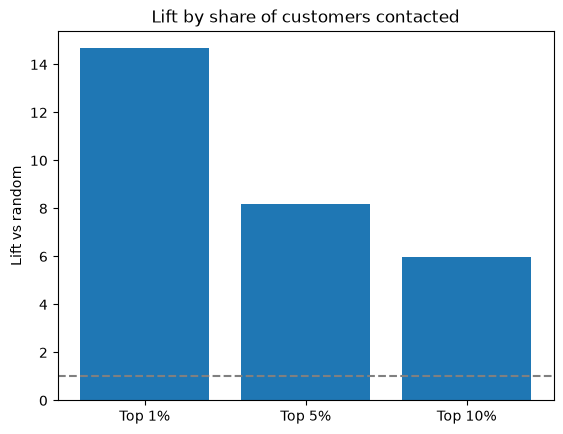

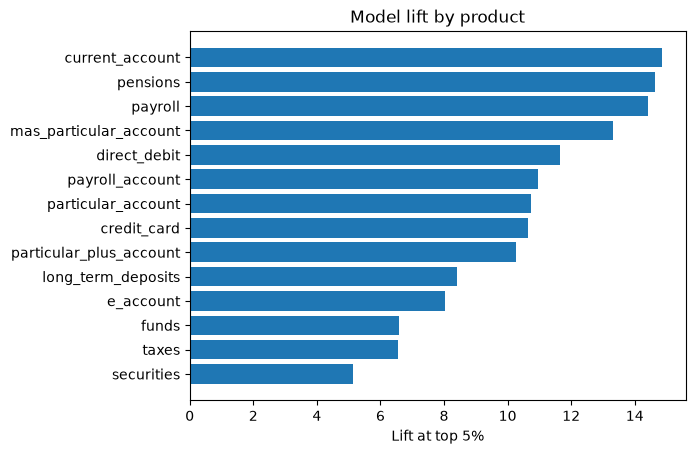

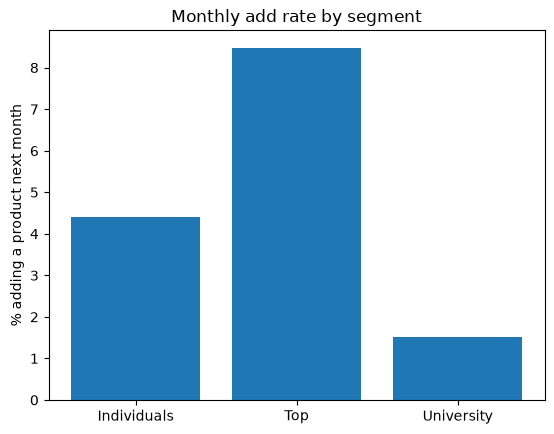

In [90]:
import os
os.makedirs("../charts", exist_ok=True)

# 1. Lift by contact size
ks = ["Top 1%", "Top 5%", "Top 10%"]
lifts = [14.67, 8.19, 5.99]
plt.bar(ks, lifts); plt.axhline(1, color="grey", linestyle="--")
plt.ylabel("Lift vs random"); plt.title("Lift by share of customers contacted")
plt.savefig("../charts/lift_by_cutoff.png", dpi=150, bbox_inches="tight"); plt.show()

# 2. Lift by product (top 5%)
prod = pd.DataFrame(results, columns=["product", "base", "rate", "lift"]).dropna().sort_values("lift")
plt.barh(prod["product"], prod["lift"]); plt.xlabel("Lift at top 5%")
plt.title("Model lift by product")
plt.savefig("../charts/lift_by_product.png", dpi=150, bbox_inches="tight"); plt.show()

# 3. Add rate by segment
seg_rate = test_df.groupby("segment", observed=True)["y"].mean().drop("Unknown")
plt.bar(seg_rate.index, seg_rate.values * 100); plt.ylabel("% adding a product next month")
plt.title("Monthly add rate by segment")
plt.savefig("../charts/add_rate_by_segment.png", dpi=150, bbox_inches="tight"); plt.show()